# Tutoriel bstock : du parc vide aux graphiques

bstock structure les données d'un parc de bâtiments (sites, bâtiments, enveloppes, systèmes,
compteurs) et garde, pour chaque valeur, **d'où elle vient**. Ce notebook suit le parcours complet
d'un projet sur un parc réel, les deux sites de Nobatek (Anglet et Bordeaux) :

1. **le modèle du projet** : étendre `Site` et `Building` avec les champs du client ;
2. **créer le parc** à partir de ce que le client sait : deux adresses ;
3. **enrichir** le parc avec les bases publiques : RNB, BDNB et DPE ;
4. **regarder** le parc : `repr`, arbre HTML, `describe()`, DataFrame ;
5. **la provenance** : données du client, audit, valeurs calculées, priorité des sources ;
6. **enveloppe et systèmes** ;
7. **sélectionner et analyser** : filtres, sommes par site, complétude, conflits ;
8. **les mesures** : compteurs, sous-compteurs, consommation, kWh/m² ;
9. **les graphiques** plotly ;
10. **sauvegarder, recharger, exporter**.

**Prérequis**

- l'extra `tutorial` (il installe aussi `plot` et `connectors`), et `geo` pour l'export
  GeoPackage :

  ```bash
  python -m pip install -e ".[tutorial,geo]"
  jupyter lab tutorial/bstock_tutorial.ipynb
  ```

- un accès à internet : la partie 3 appelle les API publiques. Leurs réponses peuvent évoluer
  (nouveau millésime de la BDNB, nouveaux DPE) : les nombres affichés peuvent alors différer
  légèrement de ceux cités dans le texte.

Les données du client (inventaire, audit, relevés de compteurs) sont **fictives** et générées
dans le notebook.

## 0. Les notions de base

```
BuildingPark  "Nobatek"                       ← le parc, et la priorité des sources
├── Site  nobatek-anglet                      ← site du client (les sites s'imbriquent)
│   ├── Site  bdnb-bg-…                       ← groupe de bâtiments de la BDNB
│   │   ├── Building  GJ2P6KGVQGAA            ← bâtiment, identifié par son id RNB
│   │   └── Building  8PDAQ6GZAHZ3
│   └── Building  QEQC8WX97T4B
└── Site  nobatek-bordeaux
    └── Building  TRKDH5MARXP4
Meter  TGBT_ANGLET  scope=[nobatek-anglet]    ← les compteurs sont rangés à part, avec leur périmètre
```

- Chaque site ou bâtiment porte des **champs sourcés** (`construction_year`, `heated_area`…),
  une **enveloppe** et des **systèmes** (chauffage, ECS, PV…).
- Un champ sourcé ne stocke pas une valeur mais une **liste de candidats** : valeur, source
  (`"bdnb"`, `"dpe"`, `"audit"`…), date, référence. La **priorité des sources** du parc choisit la
  **valeur effective**, celle qu'on lit avec `building.construction_year`.
- Les champs **intensifs** (année, usage, hauteur, U…) sont **hérités** du site quand le bâtiment
  n'a pas de valeur propre. Les champs **extensifs** (surfaces, nombre de logements, puissances)
  ne le sont jamais : on les additionne.
- Chaque champ a une **unité fixe**, déclarée avec le champ (m², kW, W/(m².K)…).

In [1]:
import math
import tempfile
from datetime import date
from pathlib import Path

import pandas as pd
import plotly.io as pio

import bstock
from bstock import (
    Building,
    BuildingPark,
    Channel,
    CsvReader,
    DHWGenerator,
    EnvelopeComponent,
    HeatingGenerator,
    Meter,
    MissingDependencyError,
    Site,
    SolarPV,
    SourcePriority,
    Window,
    sourced,
)
from bstock.connectors import bdnb, dpe, rnb

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)
# interactive figures in Jupyter, plus a PNG copy (kaleido) that GitHub can display
pio.renderers.default = "notebook_connected+png"

OUTPUT = Path(tempfile.gettempdir()) / "bstock_tutorial"  # files written by the tutorial
OUTPUT.mkdir(parents=True, exist_ok=True)
print(f"bstock {bstock.__version__}, files in {OUTPUT}")

bstock 0.12.0, files in C:\Users\BDURAN~1\AppData\Local\Temp\bstock_tutorial


## 1. Le modèle du projet

Le modèle de base couvre ce que donnent les sources publiques. Un projet ajoute ses propres champs
en sous-classant `Site` et `Building`, avec `sourced(...)` : ces champs ont eux aussi une
provenance, une unité, et se retrouvent partout (DataFrame, sélections, sommes, sauvegarde).

- `inherit=True` : champ intensif, hérité du site parent ;
- `extensive=True` : champ additionnable, jamais hérité, sommé par `aggregate()`.

In [2]:
class NobatekSite(Site):
    """Site with the Nobatek team in charge."""

    team = sourced(str, inherit=True, description="Team in charge of the site")


class NobatekBuilding(Building):
    """Building with the asset code and the area rented by Nobatek."""

    asset_code = sourced(str, description="Code in the client inventory")
    rented_area = sourced(float, unit="m²", ge=0, extensive=True, description="Rented area")


fields = NobatekBuilding.sourced_fields()
pd.DataFrame(
    [
        {"field": n, "unit": f.unit, "inherit": f.inherit, "extensive": f.extensive}
        for n, f in fields.items()
    ]
).set_index("field").T

field,name,address,municipality,insee_code,lat,lon,usage,sub_usages,construction_year,level_count,height,dwelling_count,footprint,footprint_area,floor_area,heated_area,asset_code,rented_area
unit,NaN,NaN,NaN,NaN,°,°,NaN,NaN,NaN,NaN,m,NaN,NaN,m²,m²,m²,NaN,m²
inherit,False,True,True,True,True,True,True,True,True,True,True,False,False,False,False,False,False,False
extensive,False,False,False,False,False,False,False,False,False,False,False,True,False,True,True,True,False,True


## 2. Créer le parc

Le parc connaît les classes du projet (`site_cls`, `building_cls`) : `new_site` et
`new_building` les instancient, et le rechargement d'une sauvegarde aussi.

Au départ, le client ne donne que ses deux sites et leur adresse. Les valeurs passées à
`new_site` reçoivent la source indiquée par `source` (`"manual"` sinon).

In [3]:
OWNER_SOURCE = "nobatek"

park = BuildingPark(name="Nobatek", site_cls=NobatekSite, building_cls=NobatekBuilding)
park.new_site(
    "nobatek-anglet",
    name="Nobatek Anglet",
    address="67 rue de Mirambeau 64600 Anglet",
    team="Sud-Ouest",
    source=OWNER_SOURCE,
)
park.new_site(
    "nobatek-bordeaux",
    name="Nobatek Bordeaux",
    address="9 rue Jean-Paul Alaux, 33100 Bordeaux",
    team="Bordeaux",
    source=OWNER_SOURCE,
)
park

BuildingPark 'Nobatek': 2 sites, 0 buildings, 0 meters
├── [site] nobatek-anglet  Nobatek Anglet  (0 buildings)
└── [site] nobatek-bordeaux  Nobatek Bordeaux  (0 buildings)

Dans Jupyter, un parc (comme un site ou une sélection) s'affiche en **arbre HTML dépliable**.
`print()` donne la version texte, celle qu'on voit dans une console ; elle est coupée à 30 lignes
(`park.tree()` donne l'arbre complet).

In [4]:
print(park)

BuildingPark 'Nobatek': 2 sites, 0 buildings, 0 meters
├── [site] nobatek-anglet  Nobatek Anglet  (0 buildings)
└── [site] nobatek-bordeaux  Nobatek Bordeaux  (0 buildings)


## 3. Enrichir avec les bases publiques

Trois connecteurs, à lancer dans cet ordre (`bstock.connectors`, extra `[connectors]`) :

| Connecteur | Base | Apporte |
|---|---|---|
| `rnb` | Référentiel national des bâtiments | les bâtiments, leur id RNB, point, emprise, adresse |
| `bdnb` | Base de données nationale des bâtiments (CSTB) | année, usage, hauteur, niveaux, logements, générateurs |
| `dpe` | DPE open data (ADEME) | surfaces, enveloppe, générateurs du DPE le plus récent |

Chaque connecteur renvoie un **rapport** (`ImportReport`) : ce qui a été créé, enrichi, non trouvé,
et pourquoi. Les cas attendus (bâtiment absent d'une base…) sont dans le rapport, pas en
avertissement. Relancer un connecteur met ses valeurs à jour sans rien dupliquer.

### 3.1 RNB : trouver les bâtiments à chaque adresse

L'API du RNB géocode l'adresse avec la BAN et renvoie les bâtiments de la parcelle adressée.

In [5]:
rnb_client = rnb.RnbClient()
rnb_reports = {
    site.id: rnb.add_buildings_at_address(park, site.address, parent=site, client=rnb_client)
    for site in list(park.iter_sites())
}
pd.concat({site_id: r.to_dataframe() for site_id, r in rnb_reports.items()}, names=["site"])

created  enriched  not_found  ambiguous message
site             id                                                           
nobatek-anglet   GJ2P6KGVQGAA     True     False      False      False    None
                 QEQC8WX97T4B     True     False      False      False    None
                 8PDAQ6GZAHZ3     True     False      False      False    None
nobatek-bordeaux TRKDH5MARXP4     True     False      False      False    None

Les bâtiments sont créés avec la classe du projet (`NobatekBuilding`) et rangés sous leur site.
`fields=` affiche des valeurs effectives dans l'arbre. L'adresse du bâtiment vient du RNB : c'est
sa valeur propre, qui l'emporte sur celle du site dont il hériterait sinon.

In [6]:
park.tree(fields=["address", "lat", "lon"])

BuildingPark 'Nobatek': 2 sites, 4 buildings, 0 meters
├── [site] nobatek-anglet  Nobatek Anglet  (3 buildings)  address='67 rue de Mirambeau 64600 Anglet', lat=None, lon=None
│   ├── [building] GJ2P6KGVQGAA  address='67 Rue de Mirambeau, 64600 Anglet', lat=43.4742178588418 °, lon=-1.509840436098853 °
│   ├── [building] QEQC8WX97T4B  address='67 Rue de Mirambeau, 64600 Anglet', lat=43.474036388837426 °, lon=-1.509445965196382 °
│   └── [building] 8PDAQ6GZAHZ3  address='67 Rue de Mirambeau, 64600 Anglet', lat=43.47414123785522 °, lon=-1.509386325626476 °
└── [site] nobatek-bordeaux  Nobatek Bordeaux  (1 building)  address='9 rue Jean-Paul Alaux, 33100 Bordeaux', lat=None, lon=None
    └── [building] TRKDH5MARXP4  address='5 Rue Jean Paul Alaux, 33100 Bordeaux', lat=44.843601044434976 °, lon=-0.563796146591252 °

### 3.2 BDNB : année, usage, hauteur… et les groupes de bâtiments

La BDNB range les bâtiments par **groupe** (`batiment_groupe`). Quand un groupe compte plusieurs
bâtiments, `bdnb.enrich` crée un **sous-site** pour le groupe, y déplace les bâtiments, et y pose
les valeurs du groupe : les bâtiments en héritent (champs intensifs). Les valeurs propres à chaque
bâtiment (hauteur, emprise) restent sur le bâtiment. Le rapport indique chaque déplacement.

In [7]:
bdnb_report = bdnb.enrich(park)
bdnb_report.to_dataframe()

,created,enriched,not_found,ambiguous,message
id,,,,,
bdnb-bg-TCE9-WLPK-ZQTR,True,True,False,False,NaN
GJ2P6KGVQGAA,False,True,False,False,moved from nobatek-anglet into the group site bdnb-bg-TC...
8PDAQ6GZAHZ3,False,True,False,False,moved from nobatek-anglet into the group site bdnb-bg-TC...
TRKDH5MARXP4,False,True,False,False,NaN
QEQC8WX97T4B,False,False,True,False,no BDNB construction for RNB id QEQC8WX97T4B


In [8]:
park.tree(fields=["usage", "construction_year", "height"])

BuildingPark 'Nobatek': 3 sites, 4 buildings, 0 meters
├── [site] nobatek-anglet  Nobatek Anglet  (3 buildings)  usage=None, construction_year=None, height=None
│   ├── [site] bdnb-bg-TCE9-WLPK-ZQTR  (2 buildings)  usage='tertiary', construction_year=2009, height=9.0 m
│   │   ├── [building] GJ2P6KGVQGAA  usage='tertiary', construction_year=2009, height=3.6 m
│   │   └── [building] 8PDAQ6GZAHZ3  usage='tertiary', construction_year=2009, height=14.1 m
│   └── [building] QEQC8WX97T4B  usage=None, construction_year=None, height=None
└── [site] nobatek-bordeaux  Nobatek Bordeaux  (1 building)  usage=None, construction_year=None, height=None
    └── [building] TRKDH5MARXP4  usage='tertiary', construction_year=2009, height=21.1 m

L'offre ouverte de la BDNB sert 10 lignes par appel, sans clé. Pour un grand parc, passer un
client avec clé : `bdnb.enrich(park, client=bdnb.BdnbClient(api_key=...))`.

### 3.3 DPE : le diagnostic le plus récent de chaque bâtiment

Les DPE sont cherchés par id RNB (et par les numéros déjà connus dans `dpe_ids`). Les valeurs du
DPE le plus récent à l'échelle du bâtiment vont sur l'entité qui le porte : surfaces, `u_bat`,
inertie, un composant d'enveloppe par type, générateurs.

In [9]:
dpe_report = dpe.enrich(park)
dpe_report.to_dataframe()

,created,enriched,not_found,ambiguous,message
id,,,,,
QEQC8WX97T4B,False,False,True,False,no DPE found
GJ2P6KGVQGAA,False,False,True,False,no DPE found
8PDAQ6GZAHZ3,False,False,True,False,no DPE found
TRKDH5MARXP4,False,False,True,False,no DPE found


Pour ces bureaux, l'ADEME n'a pas de DPE rattaché à un id RNB : le rapport le dit, et rien
n'est inventé. Quand on connaît le numéro d'un DPE, on peut le donner à l'entité
(`dpe_ids`) puis relancer `dpe.enrich(park)`.

Le parc a maintenant un sous-site BDNB sous Anglet. On garde des noms pour les entités utilisées
dans la suite (leurs ids viennent des API, on ne les écrit pas en dur).

In [10]:
anglet, bordeaux = park["nobatek-anglet"], park["nobatek-bordeaux"]
main_building = max(anglet.iter_buildings(), key=lambda b: b.footprint_area or 0)
bordeaux_building = next(bordeaux.iter_buildings())
print(f"main Anglet building: {main_building.id}, under {main_building.parent.id}")
print(f"Bordeaux building: {bordeaux_building.id}")
park

main Anglet building: 8PDAQ6GZAHZ3, under bdnb-bg-TCE9-WLPK-ZQTR
Bordeaux building: TRKDH5MARXP4


BuildingPark 'Nobatek': 3 sites, 4 buildings, 0 meters
├── [site] nobatek-anglet  Nobatek Anglet  (3 buildings)
│   ├── [site] bdnb-bg-TCE9-WLPK-ZQTR  (2 buildings)
│   │   ├── [building] GJ2P6KGVQGAA
│   │   └── [building] 8PDAQ6GZAHZ3
│   └── [building] QEQC8WX97T4B
└── [site] nobatek-bordeaux  Nobatek Bordeaux  (1 building)
    └── [building] TRKDH5MARXP4

## 4. Regarder le parc

### 4.1 Les `repr`

Les conteneurs (parc, site, sélection) s'affichent en arbre ; les autres entités (bâtiment,
enveloppe, système, compteur) sur **une ligne**, avec leurs valeurs principales.

In [11]:
main_building

NobatekBuilding(id='8PDAQ6GZAHZ3', parent='bdnb-bg-TCE9-WLPK-ZQTR')

In [12]:
main_building.parent  # a site: a tree, like the park

[site] bdnb-bg-TCE9-WLPK-ZQTR  (2 buildings)
├── [building] GJ2P6KGVQGAA
└── [building] 8PDAQ6GZAHZ3

### 4.2 `tree()` et ses options

- `fields=` : valeurs effectives sur chaque ligne, avec leur unité ;
- `max_depth=` : nombre de niveaux affichés, le reste est compté ;
- `systems=True`, `meters=True` : systèmes et compteurs sous chaque entité (parties 6 et 8).

Le résultat est un `TreeView` : HTML dans Jupyter, texte avec `print()` ou `str()`.

In [13]:
park.tree(max_depth=1)

BuildingPark 'Nobatek': 3 sites, 4 buildings, 0 meters
├── [site] nobatek-anglet  Nobatek Anglet  (3 buildings)
│   └── … 1 site, 3 buildings
└── [site] nobatek-bordeaux  Nobatek Bordeaux  (1 building)
    └── … 1 building

In [14]:
print(park.tree(fields=["footprint_area", "height"]))

BuildingPark 'Nobatek': 3 sites, 4 buildings, 0 meters
├── [site] nobatek-anglet  Nobatek Anglet  (3 buildings)  footprint_area=None, height=None
│   ├── [site] bdnb-bg-TCE9-WLPK-ZQTR  (2 buildings)  footprint_area=430.0 m², height=9.0 m
│   │   ├── [building] GJ2P6KGVQGAA  footprint_area=84.0 m², height=3.6 m
│   │   └── [building] 8PDAQ6GZAHZ3  footprint_area=346.0 m², height=14.1 m
│   └── [building] QEQC8WX97T4B  footprint_area=None, height=None
└── [site] nobatek-bordeaux  Nobatek Bordeaux  (1 building)  footprint_area=None, height=None
    └── [building] TRKDH5MARXP4  footprint_area=2569.0 m², height=21.1 m


### 4.3 `describe()` : toutes les valeurs d'une entité et leur provenance

Une ligne par champ sourcé : valeur effective, unité, source, `provider` (l'entité qui donne la
valeur, un site si elle est héritée) et nombre de candidats propres. Ici, `usage` et
`construction_year` viennent du groupe BDNB.

In [15]:
main_building.describe().dropna(subset=["value"])

,value,unit,source,provider,inherited,candidates
field,,,,,,
address,"67 Rue de Mirambeau, 64600 Anglet",NaN,rnb,8PDAQ6GZAHZ3,False,1
municipality,Anglet,NaN,rnb,8PDAQ6GZAHZ3,False,1
insee_code,64024,NaN,rnb,8PDAQ6GZAHZ3,False,1
lat,43.474141,°,rnb,8PDAQ6GZAHZ3,False,1
lon,-1.509386,°,rnb,8PDAQ6GZAHZ3,False,1
usage,tertiary,NaN,bdnb,bdnb-bg-TCE9-WLPK-ZQTR,True,0
construction_year,2009,NaN,bdnb,bdnb-bg-TCE9-WLPK-ZQTR,True,0
level_count,1,NaN,bdnb,bdnb-bg-TCE9-WLPK-ZQTR,True,0
height,14.1,m,bdnb,8PDAQ6GZAHZ3,False,1


### 4.4 Le parc en DataFrame

`to_dataframe()` donne une ligne par bâtiment (ou par site avec `"site"`) et une colonne par champ,
valeurs effectives et héritage compris. `provenance=True` ajoute `<champ>_source` et
`<champ>_provider`.

In [16]:
columns = ["parent_id", "usage", "construction_year", "construction_year_provider"]
columns += ["height", "height_source", "footprint_area", "footprint_area_source"]
park.to_dataframe(provenance=True)[columns]

,parent_id,usage,construction_year,construction_year_provider,height,height_source,footprint_area,footprint_area_source
id,,,,,,,,
QEQC8WX97T4B,nobatek-anglet,NaN,<NA>,NaN,NaN,NaN,NaN,NaN
GJ2P6KGVQGAA,bdnb-bg-TCE9-WLPK-ZQTR,tertiary,2009,bdnb-bg-TCE9-WLPK-ZQTR,3.6,bdnb,84.0,bdnb
8PDAQ6GZAHZ3,bdnb-bg-TCE9-WLPK-ZQTR,tertiary,2009,bdnb-bg-TCE9-WLPK-ZQTR,14.1,bdnb,346.0,bdnb
TRKDH5MARXP4,nobatek-bordeaux,tertiary,2009,TRKDH5MARXP4,21.1,bdnb,2569.0,bdnb


## 5. La provenance des valeurs

### 5.1 Les données du client

Le client fournit un inventaire, avec les id RNB de ses bâtiments. Chaque valeur est posée avec
`set()`, qui garde la source, la date et une référence (ici la ligne de l'inventaire). Une valeur
manquante (`NaN`) n'est simplement pas posée.

In [17]:
INVENTORY_SOURCE = "nobatek_inventory_2026"
inventory = pd.DataFrame(
    [  # made-up client data
        ("GJ2P6KGVQGAA", "ANG-01", 80.0, 75.0),
        ("8PDAQ6GZAHZ3", "ANG-02", 1050.0, 980.0),
        ("QEQC8WX97T4B", "ANG-03", None, None),  # technical room
        ("TRKDH5MARXP4", "BDX-01", None, 650.0),  # Nobatek rents part of the building
    ],
    columns=["rnb_id", "asset_code", "heated_area", "rented_area"],
)

for row in inventory.itertuples():
    building = park.get_by_rnb(row.rnb_id)
    if building is None:  # the RNB may have changed since this tutorial was written
        print(f"{row.rnb_id} not in the park")
        continue
    for name in ("asset_code", "heated_area", "rented_area"):
        value = getattr(row, name)
        if pd.notna(value):
            building.set(
                name, value, source=INVENTORY_SOURCE, date=date(2026, 1, 15), ref=f"row {row.Index}"
            )

park.tree(fields=["asset_code", "heated_area", "rented_area"])

BuildingPark 'Nobatek': 3 sites, 4 buildings, 0 meters
├── [site] nobatek-anglet  Nobatek Anglet  (3 buildings)  heated_area=None
│   ├── [site] bdnb-bg-TCE9-WLPK-ZQTR  (2 buildings)  heated_area=None
│   │   ├── [building] GJ2P6KGVQGAA  asset_code='ANG-01', heated_area=80.0 m², rented_area=75.0 m²
│   │   └── [building] 8PDAQ6GZAHZ3  asset_code='ANG-02', heated_area=1050.0 m², rented_area=980.0 m²
│   └── [building] QEQC8WX97T4B  asset_code='ANG-03', heated_area=None, rented_area=None
└── [site] nobatek-bordeaux  Nobatek Bordeaux  (1 building)  heated_area=None
    └── [building] TRKDH5MARXP4  asset_code='BDX-01', heated_area=None, rented_area=650.0 m²

Une affectation directe (`building.name = ...`) pose un candidat de source `"manual"`, en tête de
la priorité par défaut.

In [18]:
bordeaux_building.name = "Bureaux Nobatek Bordeaux"
bordeaux_building.effective("name")

SourcedValue(value='Bureaux Nobatek Bordeaux', source='manual', date=None, comment=None, ref=None, raw=None)

### 5.2 Plusieurs sources pour une même valeur

Une campagne d'audit (fictive) donne une autre année de construction pour le bâtiment principal
d'Anglet. Le bâtiment a désormais une valeur propre, qui l'emporte sur la valeur héritée du
groupe BDNB. `inherited_candidates()` liste tous les candidats le long de la chaîne d'héritage,
du plus proche au plus lointain.

In [19]:
main_building.set(
    "construction_year", 2008, source="audit", date=date(2025, 6, 3), comment="building permit"
)
print(
    f"construction_year = {main_building.construction_year}, "
    f"source {main_building.effective('construction_year').source!r}, "
    f"given by {main_building.provider_id('construction_year')!r}"
)


def candidates(entity, name: str) -> pd.DataFrame:
    """Return every candidate of ``name`` along the inheritance chain, nearest first."""
    rows = [
        {"entity": entity_id, **candidate.model_dump(exclude={"raw"})}
        for entity_id, candidate in entity.inherited_candidates(name)
    ]
    return pd.DataFrame(rows)


candidates(main_building, "construction_year")

construction_year = 2008, source 'audit', given by '8PDAQ6GZAHZ3'


,entity,value,source,date,comment,ref
0,8PDAQ6GZAHZ3,2008,audit,2025-06-03,building permit,NaN
1,bdnb-bg-TCE9-WLPK-ZQTR,2009,bdnb,None,NaN,bdnb-bg-TCE9-WLPK-ZQTR


`unset()` retire le candidat d'une source : le bâtiment retrouve alors la valeur héritée.

In [20]:
main_building.unset("construction_year", source="audit")
main_building.construction_year, main_building.provider_id("construction_year")

(2009, 'bdnb-bg-TCE9-WLPK-ZQTR')

### 5.3 Valeurs calculées et priorité des sources

`compute_footprint_area()` calcule la surface d'emprise à partir de la géométrie (sans
dépendance, par une projection locale) et la range sous la source `"computed"`, à côté de la
valeur BDNB. La **priorité par défaut** place `computed` avant `dpe`, `bdnb` et `rnb` : la valeur
calculée devient effective.

In [21]:
for building in park.iter_buildings():
    if building.footprint is not None:
        building.compute_footprint_area()

print(park.source_priority.default)
candidates(main_building, "footprint_area")

('manual', 'audit', 'computed', 'dpe', 'bdnb', 'rnb', '*', 'assumption')


,entity,value,source,date,comment,ref
0,8PDAQ6GZAHZ3,346.000000,bdnb,None,NaN,bdnb-bc-FYXA-TNB2-HX11
1,8PDAQ6GZAHZ3,345.510206,computed,None,from footprint,NaN


`conflicts()` repère les champs dont les candidats propres ne concordent pas : de quoi vérifier
une source, ou changer la priorité. Les nombres sont comparés à 5 % près par défaut : l'emprise
calculée et celle de la BDNB concordent. Avec une tolérance de 0,1 % (`rtol`), elles divergent :

In [22]:
park.select().conflicts(rtol=0.001)

,entity,field,values,retained
0,GJ2P6KGVQGAA,footprint_area,"{'bdnb': 84.0, 'computed': 84.18197375043519}",computed
1,8PDAQ6GZAHZ3,footprint_area,"{'bdnb': 346.0, 'computed': 345.5102063964886}",computed
2,TRKDH5MARXP4,footprint_area,"{'bdnb': 2569.0, 'computed': 2572.078360293711}",computed


La priorité est réglable pour tout le parc (`default`) ou **par champ** (`per_field`). `"*"`
donne son rang à toutes les sources non listées. Une `SourcePriority` est immuable : on en assigne
une nouvelle au parc. Ici, on préfère l'emprise de la BDNB à la valeur calculée :

In [23]:
park.source_priority = SourcePriority(per_field={"footprint_area": ("bdnb", "computed", "*")})
print(f"with BDNB first: {main_building.footprint_area:.1f} m²")

park.source_priority = SourcePriority()  # back to the default priority
print(f"default priority: {main_building.footprint_area:.1f} m²")

with BDNB first: 346.0 m²
default priority: 345.5 m²


## 6. Enveloppe et systèmes

### 6.1 L'enveloppe

Chaque site ou bâtiment a une `envelope` : des valeurs de synthèse (`u_bat`, `loss_area`,
`heat_loss_coefficient`, inertie…), sourcées elles aussi, et une liste optionnelle de composants
(murs, toiture, fenêtres…). Les méthodes `compute_*` dérivent les valeurs de synthèse des
composants, sous la source `"computed"`.

Ici, un audit (fictif) décrit l'enveloppe du bâtiment de Bordeaux.

In [24]:
envelope = bordeaux_building.envelope
for component in (
    EnvelopeComponent(id="walls", kind="wall", area=2400.0, u_value=0.45, source="audit"),
    EnvelopeComponent(id="roof", kind="roof", area=2569.0, u_value=0.25, source="audit"),
    EnvelopeComponent(id="floor", kind="floor", area=2569.0, u_value=0.4, source="audit"),
    Window(id="windows", area=900.0, u_value=1.8, shgc=0.4, glazing="double", source="audit"),
):
    envelope.add_component(component)
envelope.compute_heat_loss_coefficient()
envelope.compute_loss_area()
envelope.compute_u_bat()

print(envelope)
envelope.describe().dropna(subset=["value"])

Envelope(owner='TRKDH5MARXP4', loss_area=8438.0 m², heat_loss_coefficient=4369.85 W/K, u_bat=0.5178774591135341 W/(m².K), components=4)


,value,unit,source,provider,inherited,candidates
field,,,,,,
loss_area,8438.0,m²,computed,TRKDH5MARXP4,False,1
heat_loss_coefficient,4369.85,W/K,computed,TRKDH5MARXP4,False,1
u_bat,0.517877,W/(m².K),computed,TRKDH5MARXP4,False,1


### 6.2 Les systèmes

Un système appartient à un bâtiment ou à un **site** : un système de site dessert tous ses
bâtiments (ou ceux listés dans `serves`). Ici, une pompe à chaleur air/eau et un ballon d'ECS électrique
partagés par le site d'Anglet, et une installation photovoltaïque sur le bâtiment de Bordeaux.

In [25]:
park.add_system(
    HeatingGenerator(
        id="hp-anglet",
        technology="heat_pump_air_water",
        energy_type="electricity",
        nominal_power=120.0,
        seasonal_performance_ratio=3.2,
        source="audit",
    ),
    owner=anglet,
)
park.add_system(
    DHWGenerator(
        id="dhw-anglet", technology="electric_water_tank", energy_type="electricity", source="audit"
    ),
    owner=anglet,
)
park.add_system(
    SolarPV(id="pv-bordeaux", peak_power=36.0, azimuth=180.0, tilt=10.0, source="audit"),
    owner=bordeaux_building,
)

print(main_building.find_serving_systems("heating"))  # shared by its ancestor site
park.tree(systems=True)

[HeatingGenerator(id='hp-anglet', technology='heat_pump_air_water', energy_type='electricity', nominal_power=120.0 kW, owner='nobatek-anglet')]


BuildingPark 'Nobatek': 3 sites, 4 buildings, 0 meters
├── [site] nobatek-anglet  Nobatek Anglet  (3 buildings)
│   ├── [heating] hp-anglet
│   ├── [dhw] dhw-anglet
│   ├── [site] bdnb-bg-TCE9-WLPK-ZQTR  (2 buildings)
│   │   ├── [building] GJ2P6KGVQGAA
│   │   └── [building] 8PDAQ6GZAHZ3
│   └── [building] QEQC8WX97T4B
└── [site] nobatek-bordeaux  Nobatek Bordeaux  (1 building)
    └── [building] TRKDH5MARXP4  Bureaux Nobatek Bordeaux
        └── [pv] pv-bordeaux

## 7. Sélectionner et analyser

### 7.1 Les sélections

`park.select(...)` filtre les bâtiments (ou les sites avec `entity="site"`) sur leurs **valeurs
effectives, héritage compris**. Opérateurs : `__in`, `__lt`, `__le`, `__gt`, `__ge`,
`__isnull`, `__contains`, `__family`. Critères de structure : `within`, `parent`, `has_rnb_id`,
`has_meter`, `has_system`. `id` et `id__in` retiennent des entités par leur id, et
`park[[id1, id2]]` donne directement la sélection d'une liste d'ids. Les sélections se
combinent avec `|`, `&` et `-`.

In [26]:
tertiary = park.select(usage="tertiary", height__gt=10)
print(f"tertiary and higher than 10 m: {tertiary.ids}")

without_area = park.select(heated_area__isnull=True)
print(f"without heated area: {without_area.ids}")

heated = park.select(has_system="heating")  # the heat pump of the site counts
print(f"served by a heating system: {heated.ids}")

(park.select(within=anglet) - without_area).tree(fields=["heated_area"])

tertiary and higher than 10 m: ('8PDAQ6GZAHZ3', 'TRKDH5MARXP4')
without heated area: ('QEQC8WX97T4B', 'TRKDH5MARXP4')
served by a heating system: ('QEQC8WX97T4B', 'GJ2P6KGVQGAA', '8PDAQ6GZAHZ3')


Selection(entity='building', 2 entities) of BuildingPark 'Nobatek'
└── [site] nobatek-anglet  Nobatek Anglet  (2 buildings)  heated_area=None
    └── [site] bdnb-bg-TCE9-WLPK-ZQTR  (2 buildings)  heated_area=None
        ├── [building] GJ2P6KGVQGAA  heated_area=80.0 m²
        └── [building] 8PDAQ6GZAHZ3  heated_area=1050.0 m²

### 7.2 Sommer par site, sans double compte

`aggregate()` additionne les champs extensifs par site. Si un site a sa propre valeur (un DPE de
tout l'îlot) et ses bâtiments la leur, il montre les deux (`site`, `buildings`, `delta`) sans
jamais les ajouter. `coverage` donne la part des bâtiments renseignés : une valeur manquante
n'est jamais estimée. Les champs du projet (`rented_area`) et les puissances des systèmes sont
inclus.

In [27]:
totals = park.select().aggregate(["heated_area", "rented_area"])
columns = [("heated_area", "total"), ("heated_area", "coverage")]
columns += [("rented_area", "total"), ("rented_area", "coverage")]
columns += [("heating_power", "value"), ("pv_peak_power", "value"), ("building_count", "value")]
totals[columns]

quantity               heated_area           rented_area            \
measure                      total  coverage       total  coverage   
id                                                                   
nobatek-anglet              1130.0  0.666667      1055.0  0.666667   
bdnb-bg-TCE9-WLPK-ZQTR      1130.0  1.000000      1055.0  1.000000   
nobatek-bordeaux               NaN  0.000000       650.0  1.000000   
__park__                    1130.0  0.500000      1705.0  0.750000   

quantity               heating_power pv_peak_power building_count  
measure                        value         value          value  
id                                                                 
nobatek-anglet                 120.0           NaN              3  
bdnb-bg-TCE9-WLPK-ZQTR           NaN           NaN              2  
nobatek-bordeaux                 NaN          36.0              1  
__park__                       120.0          36.0              4

### 7.3 Complétude et provenance

- `completeness()` : par champ, combien d'entités ont une valeur (dont héritée) ;
  `per="entity"` donne ce qui manque bâtiment par bâtiment ;
- `provenance()` : de quelle source viennent les valeurs effectives.

In [28]:
report_fields = ["usage", "construction_year", "height", "footprint_area", "heated_area"]
buildings = park.select()
buildings.completeness(report_fields)

,filled,inherited,total,rate
field,,,,
usage,3,2,4,0.75
construction_year,3,2,4,0.75
height,3,0,4,0.75
footprint_area,4,0,4,1.00
heated_area,2,0,4,0.50


In [29]:
buildings.provenance(report_fields)

,bdnb,computed,nobatek_inventory_2026,inherited,missing
field,,,,,
usage,3,0,0,2,1
construction_year,3,0,0,2,1
height,3,0,0,0,1
footprint_area,0,4,0,0,0
heated_area,0,0,2,0,2


## 8. Les mesures

Un `Meter` mesure une ou plusieurs entités (`scope` : sites, bâtiments ou systèmes). Ses
`channels` sont les grandeurs mesurées (`energy` en kWh, `power` en W, `index`…). Les données
sont un DataFrame à index horodaté **avec fuseau horaire**, dont les colonnes suivent la
convention de **tide** : `nom__unité__bloc__sous_bloc`.

Les données viennent d'un **lecteur** (`CsvReader`, `ParquetReader`, ou un lecteur du projet), ou
sont posées directement dans `meter.data`.

### 8.1 Un compteur lu dans un CSV

À Anglet, tout est électrique : le compteur général du TGBT (tableau général basse tension) mesure
l'ensemble du site, et deux sous-compteurs mesurent la pompe à chaleur et le ballon d'ECS.

On génère (de façon fictive) les trois courbes de charge au pas de 30 minutes pour 2024 : la PAC
suit l'hiver et l'occupation, le ballon chauffe en heures creuses, le reste (éclairage,
bureautique) suit l'occupation. Le TGBT, qui en fait la somme, est écrit dans un CSV au format
d'un export de fournisseur : horodatage avec décalage UTC, séparateur `;`. Le lecteur convertit
en UTC les horodatages à décalages mixtes (heure d'hiver, heure d'été) ; un horodatage sans
fuseau demande `tz=` au lecteur (`CsvReader(..., tz="Europe/Paris")`).

In [30]:
index = pd.date_range("2024-01-01", "2025-01-01", freq="30min", tz="Europe/Paris", inclusive="left")
occupied = (index.dayofweek < 5) & (index.hour >= 8) & (index.hour < 19)
winter = [max(0.0, math.cos(2 * math.pi * (t.dayofyear - 15) / 366)) for t in index]
heat_pump = [w * (8.0 if o else 2.0) for o, w in zip(occupied, winter, strict=True)]
water_tank = [1.5 if t.hour < 6 else 0.0 for t in index]  # off-peak hours
others = [3.0 + 9.0 * o for o in occupied]  # lighting, office equipment
tgbt = [sum(kwh) for kwh in zip(heat_pump, water_tank, others, strict=True)]

load_curve = OUTPUT / "tgbt_anglet_2024.csv"
pd.DataFrame({"horodate": index.map(pd.Timestamp.isoformat), "kwh": tgbt}).to_csv(
    load_curve, sep=";", index=False
)
print(load_curve.read_text(encoding="utf-8")[:150])

horodate;kwh
2024-01-01T00:00:00+01:00;6.442513998931663
2024-01-01T00:30:00+01:00;6.442513998931663
2024-01-01T01:00:00+01:00;6.442513998931663
2024-


In [31]:
tgbt_anglet = park.add_meter(
    Meter(
        id="TGBT_ANGLET",
        name="TGBT Anglet",
        scope=[anglet.id],
        energy_type="electricity",
        end_use="total",
        timestep="30min",
        channels=[Channel(name="energy", unit="kWh", column="kwh")],
        reader=CsvReader(path=str(load_curve), index_col="horodate", sep=";"),
    )
)
tgbt_anglet.load_data()
print(tgbt_anglet)  # one-line repr: "data=loaded"
print(tgbt_anglet.tide_columns())
tgbt_anglet.data.head()

Meter(id='TGBT_ANGLET', name='TGBT Anglet', energy_type='electricity', end_use='total', scope=['nobatek-anglet'], data=loaded)
{'energy': 'TGBT_ANGLET_energy__kWh__nobatek-anglet__total'}


,TGBT_ANGLET_energy__kWh__nobatek-anglet__total
horodate,
2023-12-31 23:00:00+00:00,6.442514
2023-12-31 23:30:00+00:00,6.442514
2024-01-01 00:00:00+00:00,6.442514
2024-01-01 00:30:00+00:00,6.442514
2024-01-01 01:00:00+00:00,6.442514


### 8.2 Des sous-compteurs, avec des données posées directement

Les deux sous-compteurs d'Anglet déclarent le TGBT comme compteur parent (`parent_meter`), et
mesurent chacun un système (`scope`) : la PAC (usage `heating`) et le ballon (usage `dhw`). Les
totaux n'additionnent que les compteurs de tête ; les sous-compteurs servent à répartir la
consommation du TGBT par usage. Leurs données sont posées directement dans `meter.data`.

In [32]:
SUB_METERS = [  # id, measured system, end use, 30 min kWh
    ("PAC_ANGLET", "hp-anglet", "heating", heat_pump),
    ("ECS_ANGLET", "dhw-anglet", "dhw", water_tank),
]
for meter_id, system_id, end_use, kwh in SUB_METERS:
    meter = park.add_meter(
        Meter(
            id=meter_id,
            scope=[system_id],
            parent_meter=tgbt_anglet.id,
            energy_type="electricity",
            end_use=end_use,
            timestep="30min",
            channels=[Channel(name="energy", unit="kWh")],
        )
    )
    meter.data = pd.DataFrame({"energy": kwh}, index=index)

À Bordeaux, des relevés journaliers : l'électricité du bâtiment, et la production
photovoltaïque (usage `pv_production`), comptée **négativement** dans les bilans.

In [33]:
days = pd.date_range("2024-01-01", "2024-12-31", freq="D", tz="Europe/Paris")
cold = [max(0.0, math.cos(2 * math.pi * (d.dayofyear - 15) / 366)) for d in days]
sun = [max(0.0, math.cos(2 * math.pi * (d.dayofyear - 172) / 366)) for d in days]

DAILY_METERS = [  # id, scope, end use, daily kWh
    ("ELEC_BDX", bordeaux_building.id, "total", [180 + 60 * w for w in cold]),
    ("PV_BDX", "pv-bordeaux", "pv_production", [40 + 120 * s for s in sun]),
]
for meter_id, scope, end_use, daily in DAILY_METERS:
    meter = park.add_meter(
        Meter(
            id=meter_id,
            scope=[scope],
            energy_type="electricity",
            end_use=end_use,
            timestep="1D",
            channels=[Channel(name="energy", unit="kWh")],
        )
    )
    meter.data = pd.DataFrame({"energy": daily}, index=days)

park.tree(systems=True, meters=True)

BuildingPark 'Nobatek': 3 sites, 4 buildings, 5 meters
├── [site] nobatek-anglet  Nobatek Anglet  (3 buildings)
│   ├── [heating] hp-anglet
│   ├── [dhw] dhw-anglet
│   ├── [meter] TGBT_ANGLET  TGBT Anglet  electricity total  energy kWh  30min · loaded
│   ├── [meter] PAC_ANGLET  electricity heating  energy kWh  30min · loaded
│   ├── [meter] ECS_ANGLET  electricity dhw  energy kWh  30min · loaded
│   ├── [site] bdnb-bg-TCE9-WLPK-ZQTR  (2 buildings)
│   │   ├── [building] GJ2P6KGVQGAA
│   │   └── [building] 8PDAQ6GZAHZ3
│   └── [building] QEQC8WX97T4B
└── [site] nobatek-bordeaux  Nobatek Bordeaux  (1 building)
    └── [building] TRKDH5MARXP4  Bureaux Nobatek Bordeaux
        ├── [pv] pv-bordeaux
        ├── [meter] ELEC_BDX  electricity total  energy kWh  1D · loaded
        └── [meter] PV_BDX  electricity pv_production  energy kWh  1D · loaded

### 8.3 Toutes les séries en un DataFrame, au format tide

`park.timeseries()` assemble les données des compteurs (filtrables par usage, énergie, entité…)
sans rééchantillonner : il est prêt pour `tide.Plumber`. Le nom de colonne porte l'id du compteur
et la grandeur, l'unité, le bloc (l'entité mesurée) et le sous-bloc (l'usage).

In [34]:
frame = park.timeseries(tz="Europe/Paris")
frame.columns.to_list()

['TGBT_ANGLET_energy__kWh__nobatek-anglet__total',
 'PAC_ANGLET_energy__kWh__hp-anglet__heating',
 'ECS_ANGLET_energy__kWh__dhw-anglet__dhw',
 'ELEC_BDX_energy__kWh__TRKDH5MARXP4__total',
 'PV_BDX_energy__kWh__pv-bordeaux__pv_production']

Les compteurs ont des pas de temps différents (30 min, jour) : la jointure laisse des trous. Pour
un aperçu journalier, on rééchantillonne avec pandas (tide le fait de façon plus complète).

In [35]:
frame.resample("D").sum(min_count=1).loc["2024-01-14":"2024-01-17"]

,TGBT_ANGLET_energy__kWh__nobatek-anglet__total,PAC_ANGLET_energy__kWh__hp-anglet__heating,ECS_ANGLET_energy__kWh__dhw-anglet__dhw,ELEC_BDX_energy__kWh__TRKDH5MARXP4__total,PV_BDX_energy__kWh__pv-bordeaux__pv_production
2024-01-14 00:00:00+01:00,257.985854,95.985854,18.0,239.991159,40.0
2024-01-15 00:00:00+01:00,588.000000,228.000000,18.0,240.000000,40.0
2024-01-16 00:00:00+01:00,587.966404,227.966404,18.0,239.991159,40.0
2024-01-17 00:00:00+01:00,587.865625,227.865625,18.0,239.964638,40.0


### 8.4 Énergie et températures d'une même sélection

Un `Meter` désigne **toute mesure** : un capteur est un compteur **sans `energy_type`**, avec un
canal de la grandeur mesurée (`temperature`, °C). Son rôle (`ambiance`, `outdoor`…) est porté par
`sub_bloc`. Les consommations l'ignorent ; la sélection, l'extraction et l'arbre le traitent comme
les autres compteurs. On ajoute à Anglet la température d'un bureau et celle de l'extérieur,
relevées chaque heure (données fictives).

In [36]:
hours = pd.date_range("2024-01-01", "2025-01-01", freq="h", tz="Europe/Paris", inclusive="left")
season = [math.cos(2 * math.pi * (t.dayofyear - 15) / 366) for t in hours]  # 1 in January
day = [math.sin(2 * math.pi * (t.hour - 9) / 24) for t in hours]  # warmest at 15:00

SENSORS = [  # id, name, scope, role (sub_bloc), °C
    ("T_BUREAU_ANGLET", "Bureau R+1", main_building.id, "ambiance",
     [20.5 + 1.0 * d - 0.5 * s for d, s in zip(day, season, strict=True)]),
    ("T_EXT_ANGLET", "Station extérieure", anglet.id, "outdoor",
     [14.0 + 4.0 * d - 7.0 * s for d, s in zip(day, season, strict=True)]),
]  # fmt: skip
for meter_id, name, scope, role, celsius in SENSORS:
    sensor = park.add_meter(
        Meter(
            id=meter_id,
            name=name,
            scope=[scope],
            sub_bloc=role,
            timestep="1h",
            channels=[Channel(name="temperature", unit="°C")],
        )
    )
    sensor.data = pd.DataFrame({"temperature": celsius}, index=hours)

anglet.tree(meters=True)

[site] nobatek-anglet  Nobatek Anglet  (3 buildings)
├── [meter] TGBT_ANGLET  TGBT Anglet  electricity total  energy kWh  30min · loaded
├── [meter] PAC_ANGLET  electricity heating  energy kWh  30min · loaded
├── [meter] ECS_ANGLET  electricity dhw  energy kWh  30min · loaded
├── [meter] T_EXT_ANGLET  Station extérieure  outdoor  temperature °C  1h · loaded
├── [site] bdnb-bg-TCE9-WLPK-ZQTR  (2 buildings)
│   ├── [building] GJ2P6KGVQGAA
│   └── [building] 8PDAQ6GZAHZ3
│       └── [meter] T_BUREAU_ANGLET  Bureau R+1  ambiance  temperature °C  1h · loaded
└── [building] QEQC8WX97T4B

Dans l'arbre, chaque ligne de compteur dit ce qui est mesuré : énergie et usage (ou rôle d'un
capteur), canaux et unités, pas de temps, et `· loaded` si les données sont en mémoire.

`sel.meters` donne les compteurs d'une sélection, avec la règle des consommations : pour une
sélection de sites, tous ceux de leur sous-arbre (site, bâtiments, systèmes, sous-compteurs et
capteurs compris) ; pour une sélection de bâtiments, ceux des bâtiments et de leurs sites.

In [37]:
anglet_site = park[[anglet.id]]  # a list of ids gives a selection
[meter.id for meter in anglet_site.meters]

['TGBT_ANGLET', 'PAC_ANGLET', 'ECS_ANGLET', 'T_BUREAU_ANGLET', 'T_EXT_ANGLET']

`sel.timeseries()` en extrait les données, avec les filtres de `park.timeseries()`. `quantity`
retient des canaux, et seulement leurs colonnes : énergie et températures ensemble avec
`quantity=["energy", "temperature"]`. `sub_bloc` filtre sur l'usage ou le rôle ; `energy_type`
et `end_use` ne retiennent que des compteurs d'énergie. Pour un aperçu journalier, on somme les
énergies et on moyenne les températures.

In [38]:
measures = anglet_site.timeseries(quantity=["energy", "temperature"], tz="Europe/Paris")
energy = measures.filter(like="__kWh__").resample("D").sum(min_count=1)
temperature = measures.filter(like="__°C__").resample("D").mean()
pd.concat([energy, temperature], axis=1).loc["2024-01-14":"2024-01-17"]

,TGBT_ANGLET_energy__kWh__nobatek-anglet__total,PAC_ANGLET_energy__kWh__hp-anglet__heating,ECS_ANGLET_energy__kWh__dhw-anglet__dhw,T_BUREAU_ANGLET_temperature__°C__8PDAQ6GZAHZ3__ambiance,T_EXT_ANGLET_temperature__°C__nobatek-anglet__outdoor
2024-01-14 00:00:00+01:00,257.985854,95.985854,18.0,20.000074,7.001031
2024-01-15 00:00:00+01:00,588.000000,228.000000,18.0,20.000000,7.000000
2024-01-16 00:00:00+01:00,587.966404,227.966404,18.0,20.000074,7.001031
2024-01-17 00:00:00+01:00,587.865625,227.865625,18.0,20.000295,7.004126


In [39]:
anglet_site.timeseries(quantity="temperature", sub_bloc="ambiance", tz="Europe/Paris").head(3)

,T_BUREAU_ANGLET_temperature__°C__8PDAQ6GZAHZ3__ambiance
2024-01-01 00:00:00+01:00,19.307265
2024-01-01 01:00:00+01:00,19.148346
2024-01-01 02:00:00+01:00,19.048446


Le chemin inverse : une analyse tide (un `Plumber`) désigne ses séries par leurs **blocs**, qui
sont les ids des entités (`sel.ids`). Une liste d'ids redonne une sélection : `park[ids]`
accepte tout itérable d'ids (liste, tuple, set, `pd.Index`), déduit s'il s'agit de sites ou de
bâtiments, ignore les doublons et suit l'ordre de l'arbre. Un id inconnu lève `UnknownIdError`,
un mélange de sites et de bâtiments `InvalidArgumentError`. Pour combiner la liste à d'autres
critères : `park.select(id__in=ids, ...)`.

In [40]:
blocs = pd.Index([bordeaux.id, anglet.id])  # e.g. the blocs kept by a tide Plumber
top_sites = park[blocs]
top_sites.timeseries(end_use="total", tz="Europe/Paris").resample("D").sum().head(3)

,TGBT_ANGLET_energy__kWh__nobatek-anglet__total,ELEC_BDX_energy__kWh__TRKDH5MARXP4__total
2024-01-01 00:00:00+01:00,581.446596,238.275420
2024-01-02 00:00:00+01:00,582.345609,238.512002
2024-01-03 00:00:00+01:00,583.179096,238.731341


In [41]:
park.select(id__in=blocs, entity="site", has_meter=True).ids  # Bordeaux: building meters only

('nobatek-anglet',)

L'arbre de la sélection montre d'où viennent ses mesures : avec `meters=True`, chaque site
sélectionné montre son sous-arbre (sous-sites et compteurs, sans les bâtiments), et les compteurs
de ses bâtiments apparaissent sous lui. L'arbre montre ainsi tous les compteurs de `sel.meters`.

In [42]:
top_sites.tree(meters=True)  # Bordeaux: its building meter appears under the site

Selection(entity='site', 2 entities) of BuildingPark 'Nobatek'
├── [site] nobatek-anglet  Nobatek Anglet  (3 buildings)
│   ├── [meter] TGBT_ANGLET  TGBT Anglet  electricity total  energy kWh  30min · loaded
│   ├── [meter] PAC_ANGLET  electricity heating  energy kWh  30min · loaded
│   ├── [meter] ECS_ANGLET  electricity dhw  energy kWh  30min · loaded
│   ├── [meter] T_EXT_ANGLET  Station extérieure  outdoor  temperature °C  1h · loaded
│   └── [site] bdnb-bg-TCE9-WLPK-ZQTR  (2 buildings)
│       └── [meter] T_BUREAU_ANGLET  Bureau R+1  ambiance  temperature °C  1h · loaded
└── [site] nobatek-bordeaux  Nobatek Bordeaux  (1 building)
    ├── [meter] ELEC_BDX  electricity total  energy kWh  1D · loaded
    └── [meter] PV_BDX  electricity pv_production  energy kWh  1D · loaded

### 8.5 Consommations et ratios

`consumption()` donne l'énergie finale mesurée en kWh par entité, énergie et usage, sur une
période `[start, end)` ou par mois (`freq="MS"`) ou année (`"YS"`). Rien n'est intégré ni
extrapolé : `coverage` donne la part de la période couverte par des données. Un compteur apparaît
au niveau de son périmètre : un compteur de site sur la ligne du site.

In [43]:
year = {"start": "2024-01-01", "end": "2025-01-01"}
sites = park.select(entity="site", parent=None)  # the two top-level sites
sites.consumption(**year)

,entity,energy_type,end_use,energy,coverage,estimated,meters
0,nobatek-anglet,electricity,total,133408.537229,1.0,False,[TGBT_ANGLET]
1,nobatek-bordeaux,electricity,total,72870.170937,1.0,False,[ELEC_BDX]
2,nobatek-bordeaux,electricity,pv_production,-28620.341874,1.0,False,[PV_BDX]


Le TGBT apparaît seul, en `total` : ses sous-compteurs ne sont pas ajoutés une seconde fois.
`breakdown=True` le remplace par une ligne par usage de ses sous-compteurs (`heating`, `dhw`),
plus une ligne `other` pour le reste (TGBT moins sous-compteurs).

In [44]:
sites.consumption(**year, breakdown=True)[["entity", "energy_type", "end_use", "energy"]]

,entity,energy_type,end_use,energy
0,nobatek-anglet,electricity,heating,22240.537229
1,nobatek-anglet,electricity,dhw,6588.000000
2,nobatek-anglet,electricity,other,104580.000000
3,nobatek-bordeaux,electricity,total,72870.170937
4,nobatek-bordeaux,electricity,pv_production,-28620.341874


`intensity()` ajoute la surface de référence et le ratio en kWh/m². La surface d'un site est la
somme de celles de ses bâtiments (`aggregate()`). Bordeaux n'a pas de surface chauffée :
son ratio est vide plutôt qu'estimé. Tout champ extensif peut servir de surface, y compris un
champ du projet comme `rented_area`.

In [45]:
columns = ["entity", "energy_type", "energy", "area", "intensity"]
sites.intensity(**year)[columns]

,entity,energy_type,energy,area,intensity
0,nobatek-anglet,electricity,133408.537229,1130.0,118.060652
1,nobatek-bordeaux,electricity,72870.170937,NaN,NaN
2,nobatek-bordeaux,electricity,-28620.341874,NaN,NaN


In [46]:
sites.intensity(**year, area="rented_area")[columns]

,entity,energy_type,energy,area,intensity
0,nobatek-anglet,electricity,133408.537229,1055.0,126.453590
1,nobatek-bordeaux,electricity,72870.170937,650.0,112.107955
2,nobatek-bordeaux,electricity,-28620.341874,650.0,-44.031295


In [47]:
monthly = sites.consumption(**year, freq="MS")
monthly.pivot_table(
    index="period", columns=["entity", "end_use"], values="energy", aggfunc="sum"
).head(4)

entity                    nobatek-anglet nobatek-bordeaux             
end_use                            total    pv_production        total
period                                                                
2024-01-01 00:00:00+01:00   15514.106374     -1240.000000  7417.879891
2024-02-01 00:00:00+01:00   13584.269945     -1160.000000  6703.942994
2024-03-01 00:00:00+01:00   12021.645314     -1364.265271  6499.075373
2024-04-01 00:00:00+02:00    9604.227728     -2736.923416  5515.240920

## 9. Les graphiques

Avec l'extra `[plot]`, `selection.plot` construit des figures plotly. Chaque méthode **renvoie**
une `plotly.graph_objects.Figure` sans l'afficher : Jupyter l'affiche quand elle termine la
cellule ; ailleurs, `fig.show()` ou `fig.write_html(...)`. Les entités sans valeur ne sont pas
tracées et le sous-titre dit combien elles sont.

Le renderer choisi au début du notebook (`notebook_connected+png`) enregistre chaque figure
deux fois : en HTML interactif pour Jupyter et en image PNG (via kaleido) pour les lecteurs qui
n'exécutent pas de JavaScript, comme GitHub.

### 9.1 Rapports : complétude et sources

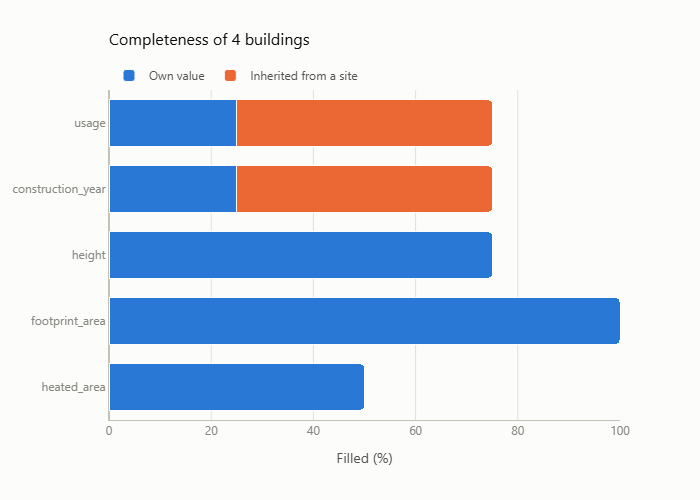

In [48]:
buildings.plot.completeness(report_fields)

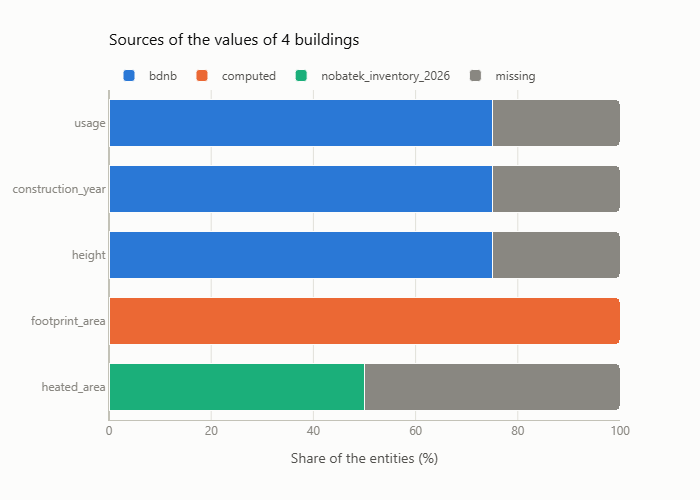

In [49]:
buildings.plot.provenance(report_fields)

### 9.2 Valeurs : sommes par site et distributions

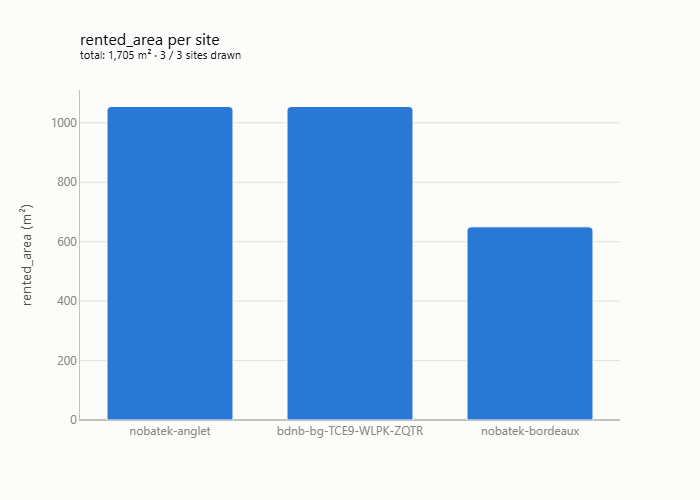

In [50]:
buildings.plot.aggregate("rented_area")

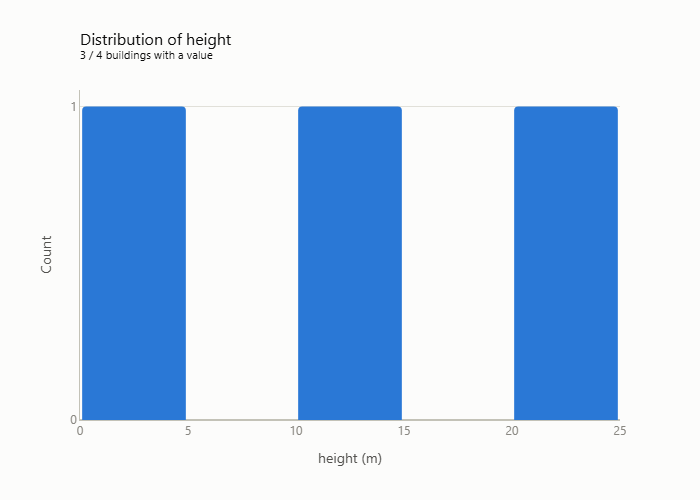

In [51]:
buildings.plot.distribution("height", bins=5)

### 9.3 Cartes

Fond OpenStreetMap, sans clé d'API. Les points utilisent `lat` / `lon` (hérités du site au
besoin), les emprises la géométrie `footprint` (GeoJSON, sans l'extra `[geo]`).

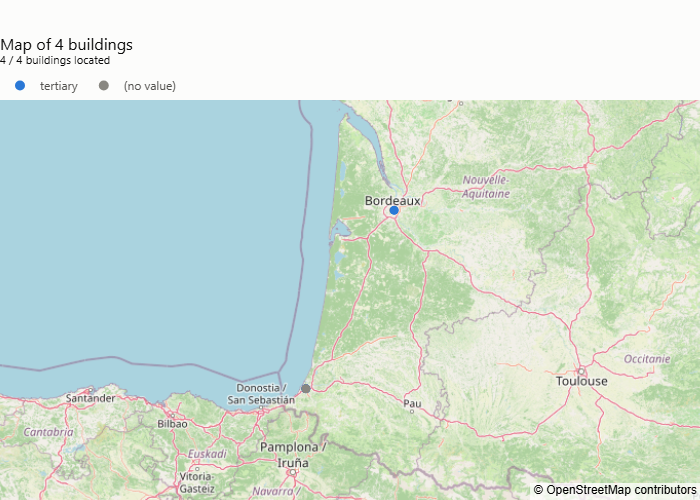

In [52]:
buildings.plot.map(color="usage")

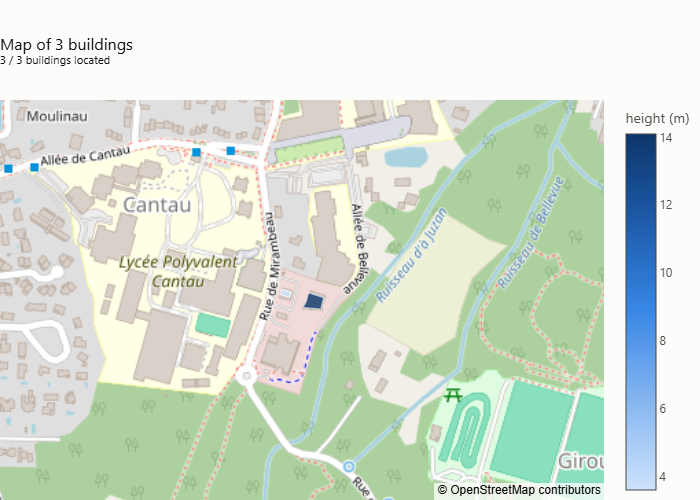

In [53]:
park.select(within=anglet).plot.map(geometry="footprint", color="height")

### 9.4 Consommations et ratios

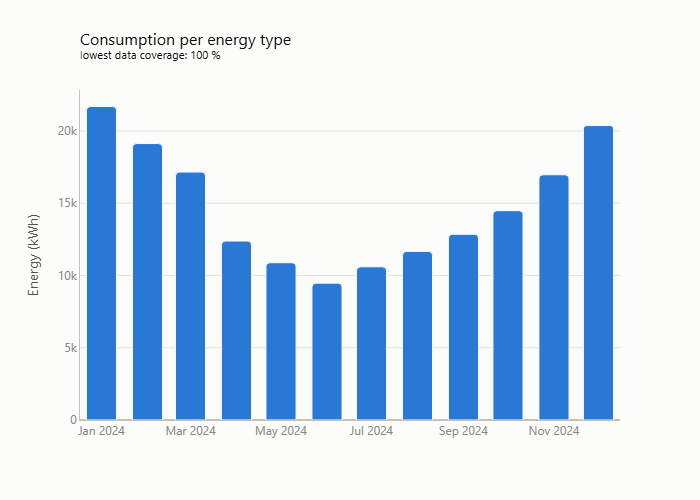

In [54]:
sites.plot.consumption(**year, freq="MS")

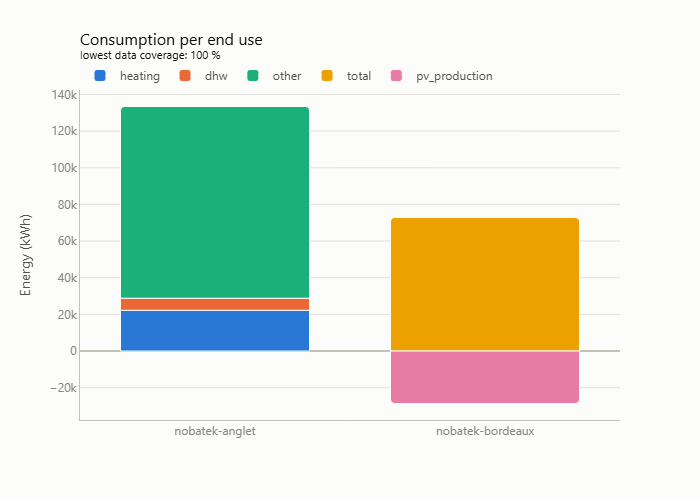

In [55]:
sites.plot.consumption(**year, by="end_use", breakdown=True)

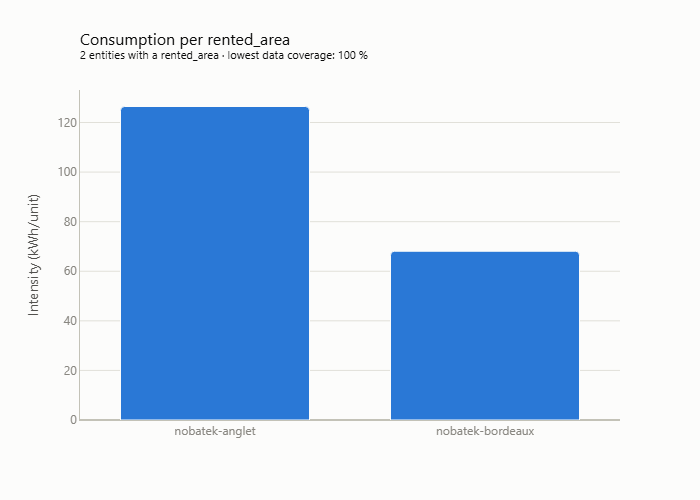

In [56]:
sites.plot.intensity(**year, area="rented_area")

Ce sont des figures plotly ordinaires : on les personnalise avant de les afficher ou de les
enregistrer.

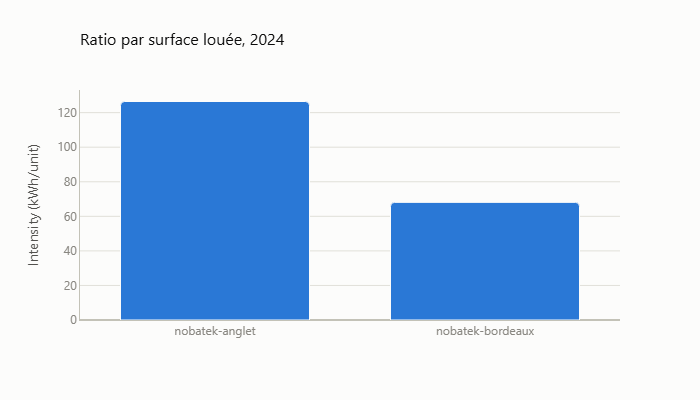

In [57]:
fig = sites.plot.intensity(**year, area="rented_area")
fig.update_layout(width=700, height=400, title_text="Ratio par surface louée, 2024")
fig.write_html(OUTPUT / "intensity.html")
fig

## 10. Sauvegarder, recharger, exporter

`save()` écrit un **répertoire de parc** : `park.json` (structure, valeurs et provenance) et, avec
`include_data=True`, les séries en Parquet, ce qui rend le répertoire autonome. `load()` le relit
avec les classes du projet.

In [58]:
park_dir = OUTPUT / "park"
park.save(park_dir, include_data=True)
sorted(p.relative_to(park_dir).as_posix() for p in park_dir.rglob("*") if p.is_file())

['park.json',
 'timeseries/ECS_ANGLET.parquet',
 'timeseries/ELEC_ANGLET.parquet',
 'timeseries/ELEC_BDX.parquet',
 'timeseries/GAZ_ANGLET.parquet',
 'timeseries/GAZ_ANGLET_ECS.parquet',
 'timeseries/PAC_ANGLET.parquet',
 'timeseries/PV_BDX.parquet',
 'timeseries/TGBT_ANGLET.parquet',
 'timeseries/T_BUREAU_ANGLET.parquet',
 'timeseries/T_EXT_ANGLET.parquet']

In [59]:
reloaded = BuildingPark.load(park_dir, site_cls=NobatekSite, building_cls=NobatekBuilding)
print(f"same park: {reloaded == park}")
print(f"class of the buildings: {type(reloaded[main_building.id]).__name__}")
print(f"source of the asset code: {reloaded[main_building.id].effective('asset_code').source}")
reloaded.tree(meters=True, max_depth=2)

same park: True
class of the buildings: NobatekBuilding
source of the asset code: nobatek_inventory_2026


BuildingPark 'Nobatek': 3 sites, 4 buildings, 7 meters
├── [site] nobatek-anglet  Nobatek Anglet  (3 buildings)
│   ├── [meter] TGBT_ANGLET  TGBT Anglet  electricity total  energy kWh  30min
│   ├── [meter] PAC_ANGLET  electricity heating  energy kWh  30min
│   ├── [meter] ECS_ANGLET  electricity dhw  energy kWh  30min
│   ├── [meter] T_EXT_ANGLET  Station extérieure  outdoor  temperature °C  1h
│   ├── [site] bdnb-bg-TCE9-WLPK-ZQTR  (2 buildings)
│   │   └── … 2 buildings
│   └── [building] QEQC8WX97T4B
└── [site] nobatek-bordeaux  Nobatek Bordeaux  (1 building)
    └── [building] TRKDH5MARXP4  Bureaux Nobatek Bordeaux

Exports pour les autres outils : DataFrame (CSV, Excel), et avec l'extra `[geo]` GeoDataFrame,
GeoPackage (couches `sites` et `buildings`, à ouvrir dans QGIS) et GeoParquet.

In [60]:
park.to_dataframe(provenance=True).to_csv(OUTPUT / "buildings.csv")
try:
    print(park.to_geopackage(OUTPUT / "nobatek.gpkg"))
except MissingDependencyError as error:
    print(f"GeoPackage skipped: {error}")

C:\Users\BDURAN~1\AppData\Local\Temp\bstock_tutorial\nobatek.gpkg


## Pour aller plus loin

- [`SPEC.md`](../SPEC.md) : la référence de conception (héritage, priorité, consommations,
  connecteurs…) ;
- [`README.md`](../README.md) : l'aide-mémoire de l'API ;
- [`examples/`](../examples) : des exemples de bout en bout, en script et en version interactive ;
- les docstrings : `help(BuildingPark.select)`, `help(bdnb.enrich)`…